# Análise exploratória e preparação do TrashNet

Este notebook examina **os dados efetivamente utilizados** e lê a auditoria e a divisão registradas. Ele não treina nem consulta resultados de modelos. As figuras são regeneradas e os exemplos são escolhidos por ordem lexicográfica entre imagens de treino, sem seleção pelo desempenho.

**Antes de executar:** instale `requirements.txt` na raiz do projeto e execute `python -m src.prepare --root .`, com `data/raw/dataset-resized.zip` disponível. Se a preparação já estiver pronta, basta executar todas as células abaixo. Dimensões são expressas como **largura × altura**. A versão de referência é `dataset-resized`, com seis classes.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "src/reporting.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro da pasta trashnet ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
from src.reporting import CLASSES, RUNS, LABELS, generate_eda, generate_report
print("Raiz do projeto:", ROOT)


Raiz do projeto: /home/joao/Documents/Codex/2026-10-21/fala-chat-em-resumo-fa-o/work/review/clean/trashnet


In [2]:
eda = generate_eda(ROOT)
audit, splits = eda["audit"], eda["splits"]
display(pd.DataFrame({
    "verificação": ["Imagens", "Semente", "Arquivos corrompidos", "Grupos duplicados (bytes)", "Grupos duplicados (pixels RGB)", "Grupos com rótulo conflitante", "Duplicatas de pixels entre conjuntos"],
    "resultado": [audit["total_images"], audit["seed"], len(audit["corrupt_files"]), len(audit["byte_duplicates"]), len(audit["pixel_duplicates"]), audit.get("label_conflict_groups", "ver auditoria"), audit.get("cross_split_pixel_duplicates", "ver célula de integridade")],
}))
display(Markdown(f"**Dimensões originais:** `{audit['dimensions']}`. **Canais/modos:** `{audit['modes']}`."))
print("SHA-256 do ZIP:", audit["zip_sha256"])
print("SHA-256 do manifesto:", audit["manifest_sha256"])


SHA-256 do ZIP: c060e8abfe5d6de0578ca15be1ed8ad0794a865d333c3473d53d1d9ad6e38b8c
SHA-256 do manifesto: 3e3a2d2ee3f9929921ab8d14a03254f1f80780995d96430dec2510096392241e


,verificação,resultado
0,Imagens,2527
1,Semente,42
2,Arquivos corrompidos,0
3,Grupos duplicados (bytes),3
4,Grupos duplicados (pixels RGB),3
5,Grupos com rótulo conflitante,3
6,Duplicatas de pixels entre conjuntos,0


**Dimensões originais:** `{'512x384': 2527}`. **Canais/modos:** `{'RGB': 2527}`.

## Integridade, duplicatas e ruído de rótulos

A auditoria decodifica as imagens e registra dimensões, modo de cor, hash dos bytes e hash dos pixels RGB. Arquivos distintos podem representar a mesma imagem: por isso, verificar somente o nome não é suficiente.

A preparação preserva as 2.527 imagens e seus rótulos originais. Grupos de pixels idênticos ficam **inteiramente no mesmo conjunto**; quando necessário, uma troca determinística com outra imagem da mesma classe preserva as contagens da estratificação. Isso impede vazamento exato, mas **não elimina rótulos contraditórios nem detecta todas as imagens visualmente parecidas**. Esse ruído é uma limitação do dataset, registrada sem corrigir rótulos pela aparência ou pelos resultados de teste.


In [3]:
duplicates = []
for group in audit["pixel_duplicates"]:
    for path, class_name in zip(group["paths"], group["classes"]):
        row = splits.loc[splits["path"] == path].iloc[0]
        duplicates.append({"hash_pixels": group["hash"][:16], "path": path, "classe": class_name, "conjunto": row["split"], "rótulo_conflitante": group["label_conflict"]})
display(pd.DataFrame(duplicates))
display(Markdown(audit.get("duplicate_policy", "Consulte audit.json para a política de duplicatas.")))
display(pd.DataFrame(audit.get("duplicate_swaps", [])))

assert not splits["path"].duplicated().any()
for column in ["sha256", "pixel_sha256"]:
    count = int((splits.groupby(column)["split"].nunique() > 1).sum())
    print(f"Grupos de {column} presentes em mais de um conjunto: {count}")
    assert count == 0
assert set(splits["split"]) == {"train", "val", "test"}
print("Verificações de identidade e não vazamento exato concluídas.")


Grupos de sha256 presentes em mais de um conjunto: 0
Grupos de pixel_sha256 presentes em mais de um conjunto: 0
Verificações de identidade e não vazamento exato concluídas.


,hash_pixels,path,classe,conjunto,rótulo_conflitante
0,7dab44930e3aeb30,data/raw/dataset-resized/glass/glass389.jpg,glass,train,True
1,7dab44930e3aeb30,data/raw/dataset-resized/plastic/plastic332.jpg,plastic,train,True
2,81c6cdae6d0800b1,data/raw/dataset-resized/glass/glass176.jpg,glass,train,True
3,81c6cdae6d0800b1,data/raw/dataset-resized/plastic/plastic152.jpg,plastic,train,True
4,c718bbee87bf9dec,data/raw/dataset-resized/glass/glass115.jpg,glass,train,True
5,c718bbee87bf9dec,data/raw/dataset-resized/metal/metal91.jpg,metal,train,True


Arquivos com pixels RGB idênticos são mantidos no mesmo conjunto. Grupos com rótulos divergentes são preservados para manter as 2.527 imagens e a distribuição de referência; trocas determinísticas de imagens da mesma classe preservam as contagens estratificadas. Nenhuma decisão utiliza métricas de modelo.

,duplicate_path,swap_path,class_name,from_split,to_split,anchor_path
0,data/raw/dataset-resized/plastic/plastic332.jpg,data/raw/dataset-resized/plastic/plastic1.jpg,plastic,val,train,data/raw/dataset-resized/glass/glass389.jpg


## Distribuição estratificada

A divisão aproximada de 70%/15%/15% usa semente 42 e é única para todos os experimentos. Arredondamentos inteiros explicam pequenas diferenças nas proporções por classe. `trash` permanece nas três partições; F1 macro dá o mesmo peso a cada uma das seis classes.


Totais por conjunto: {'train': 1768, 'val': 379, 'test': 380}


split,train,val,test,total
class_name,,,,
glass,350,75,76,501
paper,416,89,89,594
cardboard,282,61,60,403
plastic,337,72,73,482
metal,287,61,62,410
trash,96,21,20,137


split,train (%),val (%),test (%)
class_name,,,
glass,69.86,14.97,15.17
paper,70.03,14.98,14.98
cardboard,69.98,15.14,14.89
plastic,69.92,14.94,15.15
metal,70.00,14.88,15.12
trash,70.07,15.33,14.60


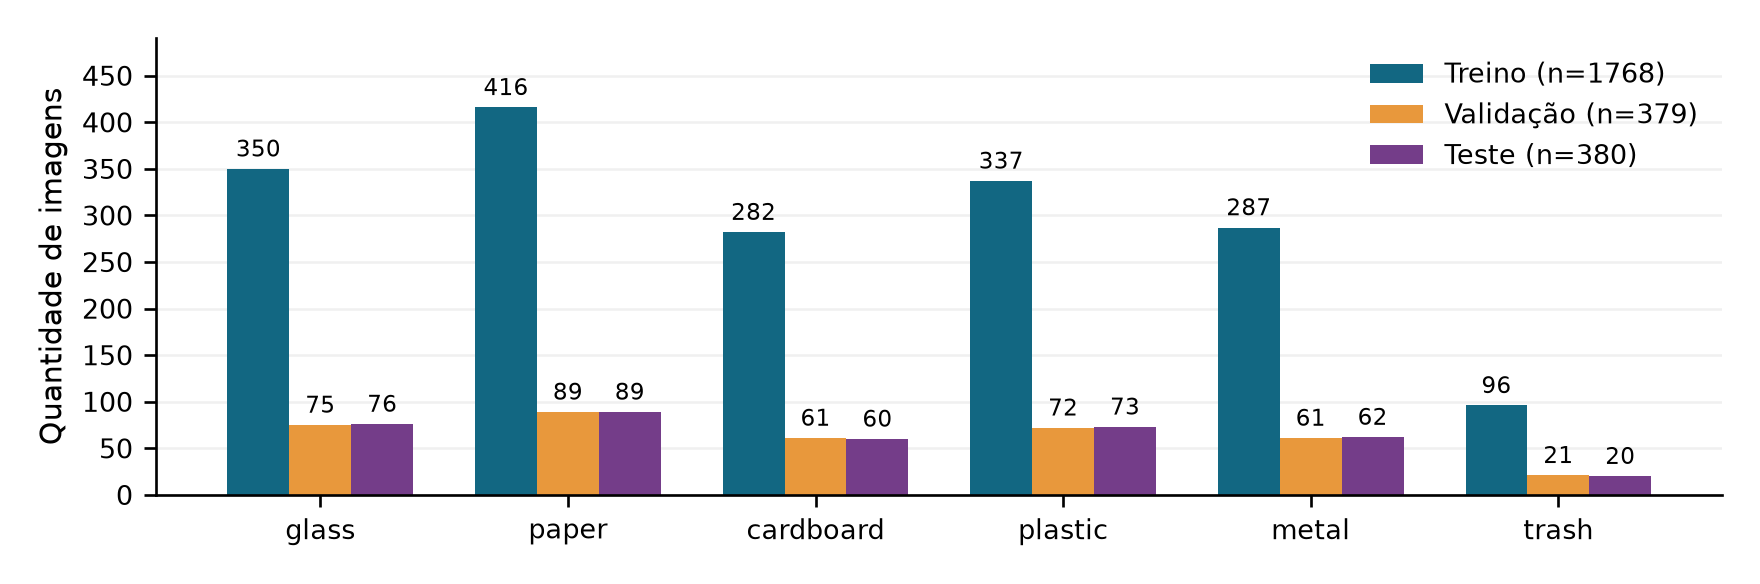

,n_treino,peso_N_sobre_Kn
class_name,,
glass,350,0.8419
paper,416,0.7083
cardboard,282,1.0449
plastic,337,0.8744
metal,287,1.0267
trash,96,3.0694


In [4]:
distribution = eda["distribution"].copy()
distribution["total"] = distribution.sum(axis=1)
display(distribution)
display((distribution[["train", "val", "test"]].div(distribution["total"], axis=0) * 100).round(2).rename(columns=lambda c: c + " (%)"))
print("Totais por conjunto:", distribution[["train", "val", "test"]].sum().to_dict())
display(Image(filename=str(ROOT / "artifacts/figures/class_distribution.png")))

train_counts = distribution["train"]
weights = train_counts.sum() / (len(CLASSES) * train_counts)
display(pd.DataFrame({"n_treino": train_counts, "peso_N_sobre_Kn": weights}).round(6))


## Exemplos e dificuldades visuais

A figura apresenta dois exemplos de treino por classe. Vidro e plástico podem ter formas e transparência semelhantes; embalagens de papel e papelão compartilham textos e padrões; metais podem exibir rótulos impressos; `trash` reúne objetos de aparência heterogênea. Iluminação, sombras, enquadramento e a área ocupada pelo objeto também variam. Essas observações motivam hipóteses de dificuldade; os erros dos modelos serão analisados separadamente.


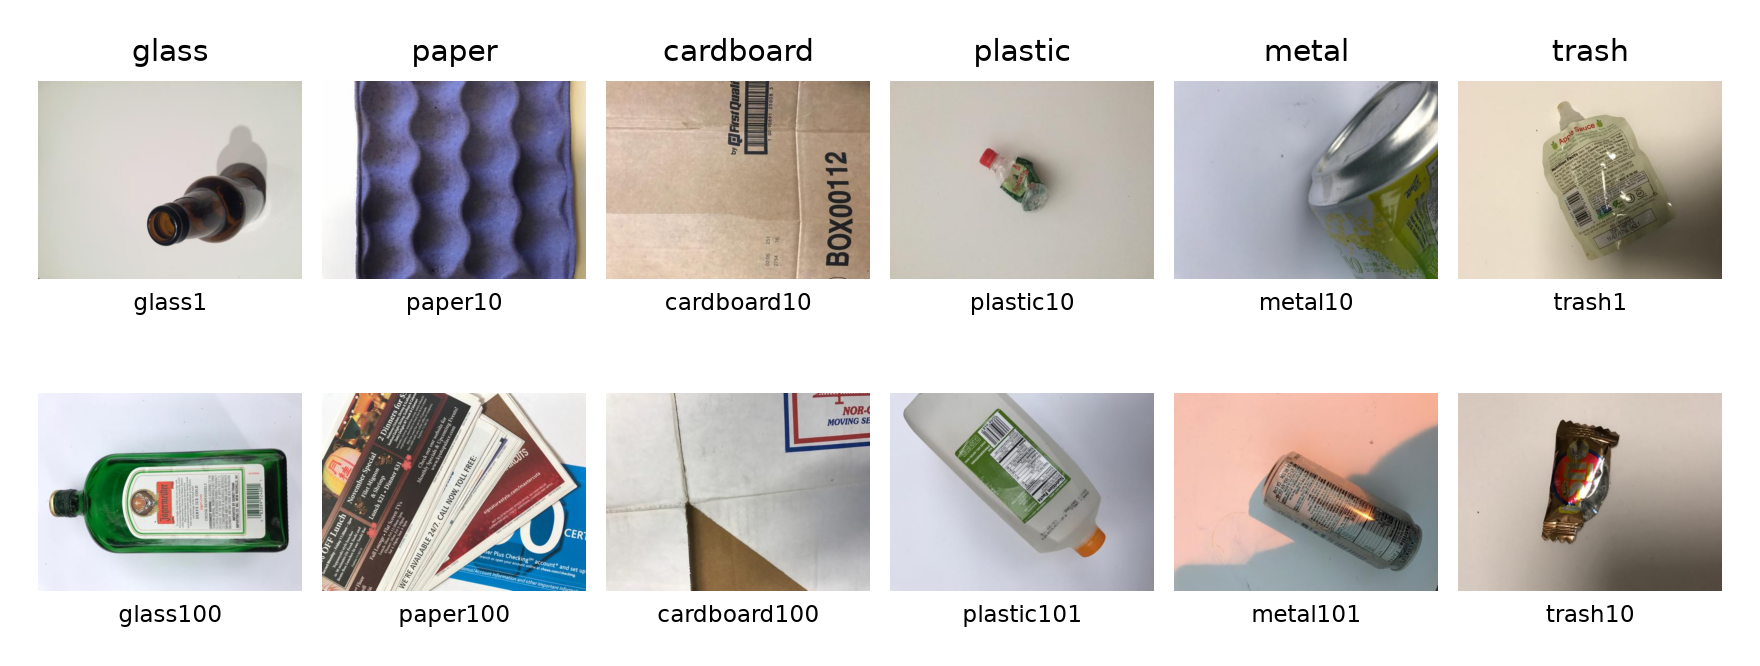

,class_name,path,split
0,glass,data/raw/dataset-resized/glass/glass1.jpg,train
1,glass,data/raw/dataset-resized/glass/glass100.jpg,train
2,paper,data/raw/dataset-resized/paper/paper10.jpg,train
3,paper,data/raw/dataset-resized/paper/paper100.jpg,train
4,cardboard,data/raw/dataset-resized/cardboard/cardboard10...,train
5,cardboard,data/raw/dataset-resized/cardboard/cardboard10...,train
6,plastic,data/raw/dataset-resized/plastic/plastic10.jpg,train
7,plastic,data/raw/dataset-resized/plastic/plastic101.jpg,train
8,metal,data/raw/dataset-resized/metal/metal10.jpg,train
9,metal,data/raw/dataset-resized/metal/metal101.jpg,train


In [5]:
display(Image(filename=str(ROOT / "artifacts/figures/class_examples.png")))
display(pd.read_csv(ROOT / "artifacts/tables/example_images.csv"))


## Resoluções e pré-processamento

Cada resolução deriva diretamente da imagem de referência em RGB. As versões de 128 × 96 e 256 × 192 usam interpolação **Lanczos**; a versão 512 × 384 preserva a resolução original. A proporção 4:3 é mantida, sem corte. Os tensores seguem a ordem canais × altura × largura do PyTorch e os pixels são divididos por 255, resultando no intervalo [0, 1]. Não se estimam estatísticas sobre validação ou teste.

Não há aumento de dados nos seis experimentos controlados. Os pesos de classe são calculados exclusivamente pelas contagens de treino, como `N / (K × n_classe)`, e aplicados somente à perda de treino nos dois experimentos ponderados. As mesmas divisões e a mesma preparação atendem a todos os modelos. As três representações de uma imagem herdam a sua partição.


{
  "path": "data/raw/dataset-resized/glass/glass1.jpg",
  "split": "train",
  "resampling": "Pillow.Resampling.LANCZOS",
  "width_height": [
    [
      128,
      96
    ],
    [
      256,
      192
    ],
    [
      512,
      384
    ]
  ]
}


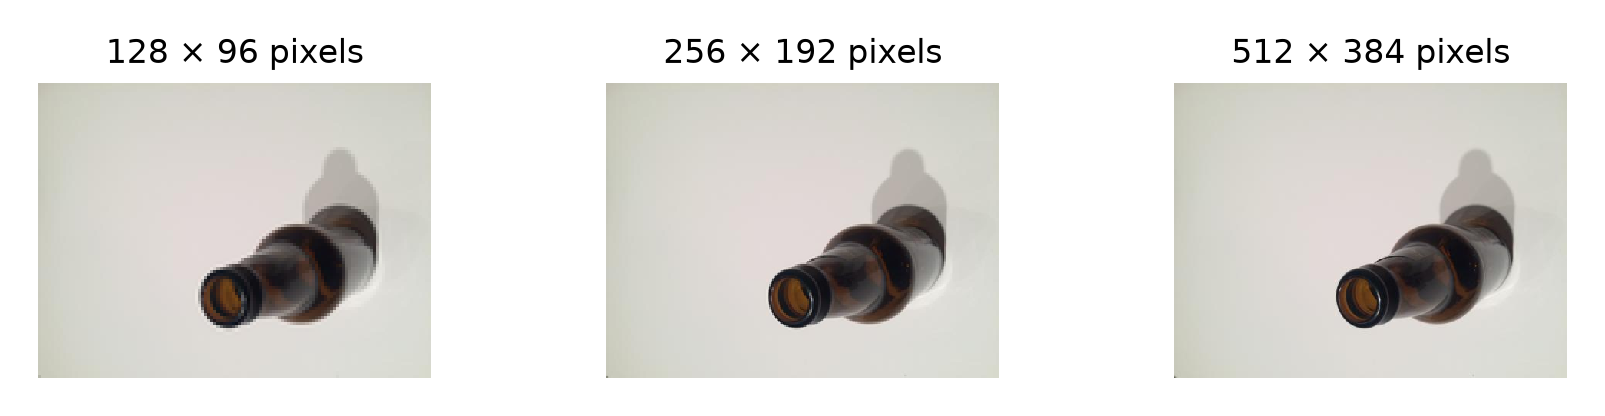

In [6]:
display(Image(filename=str(ROOT / "artifacts/figures/resolution_examples.png")))
print((ROOT / "artifacts/tables/resolution_example.json").read_text(encoding="utf-8"))


## Limitações e rastreabilidade

Os três pares de imagens idênticas com rótulos conflitantes constituem ruído supervisionado: nenhum classificador determinístico distingue duas imagens idênticas apenas pelos pixels. Mantê-los juntos elimina o vazamento entre partições, mas não o conflito. A verificação por hash não cobre quase duplicatas, outras vistas do mesmo objeto ou dependências de sessão fotográfica não anotadas.

O cenário visual relativamente controlado não representa toda a variedade de fundos, oclusões, múltiplos resíduos, sujeira e condições de iluminação do uso real. A classificação inteira da fotografia também pressupõe um rótulo único. Este estudo avalia o protocolo registrado, sem afirmar desempenho em aplicações externas.

Arquivos verificáveis: `data/audit.json`, `data/splits.csv`, `data/train.csv`, `data/val.csv`, `data/test.csv`, tabelas e figuras em `artifacts/`. A fonte do dataset e as referências completas estão no README e no artigo.
